# E7

Partant de l'exercice 4:
• Transformer les deux dimensions catégorielles binaires (dimensions booléennes) VMail, Plan et Int’l Plan en dimensions entières.

• Ajouter ces deux dimensions transformées au modèle

• Représenter la valeur du modèle optimum pour l'ensemble des clients, ventilé suivant leur type.

• Construire la matrice de confusion de ce modèle pour un seuil de 0.5 sur la valeur du modèle.

• Comment évolue cette matrice de confusion si on choisit un autre seuil?

• Faite une représentation de l'évolution de la sensibilité en fonction de l'anti-spécificité (complément à 1 de la spécificité) pour un seuil évoluant sur l'intervalle [0,1].

• Que faudrait-il pour que le modèle soit considéré comme "parfait"?

In [173]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
import random

In [ ]:
df = pd.read_csv("Churn.txt")

def transform2(x):
    if x =='yes':
        return 1
    else:
        return 0

df["Int'l Plan"] = df["Int'l Plan"].apply(transform2)
df['VMail Plan'] = df['VMail Plan'].apply(transform2)

df.head(2)

,State,Account Length,Area Code,Phone,Int'l Plan,VMail Plan,VMail Message,Day Mins,Day Calls,Day Charge,...,Eve Calls,Eve Charge,Night Mins,Night Calls,Night Charge,Intl Mins,Intl Calls,Intl Charge,CustServ Calls,Churn?
0,KS,128,415,382-4657,0,1,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.7,1,False.
1,OH,107,415,371-7191,0,1,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.7,1,False.


In [175]:
sub_df = df[['Day Charge','Eve Charge','Night Charge','CustServ Calls', 'Churn?', "Int'l Plan", "VMail Plan"]].copy()

def transform(x):
    if x == 'True.':
        return 1
    else:
        return 0

sub_df['target'] = sub_df['Churn?'].apply(transform)

# Je sais pas pk mais le prof a oublié les dimensions demandées dans l'exercice
#X = sub_df[[ 'Day Charge','Eve Charge','Night Charge','CustServ Calls', "Int'l Plan", "VMail Plan"]]

X = sub_df[[ 'Day Charge','Eve Charge','Night Charge','CustServ Calls']]
y = sub_df['target']

model = LogisticRegression()
model.fit(X, y)

model.predict_proba(X)[:,1]

array([0.23629719, 0.08109242, 0.07229537, ..., 0.20751096, 0.13506105,
       0.17060652])

# Modèle logistique 'normal' ie optimal

In [176]:
# Modèle purement hasardeux (on ne peut faire moins bien !!!)

model_df = pd.DataFrame()

model_df['target'] = y

## Modèle purement aléatoire => courbe ROC == diagonale
#model_df['proba'] = model_df.apply(lambda x: random.uniform(0, 1), axis=1)

model_df['proba'] = model.predict_proba(X)[:,1]

Modèle parfait (on ne peut faire mieux !!!)

Il faut noter que pour ce modèle, on doit injecter une connaissance sur la cible dans le modèle...

Si, dans la vie normale, vous obtenez un modèle parfait (quelle que soit la technique, deep learning ou pas, ...), posez-vous la question

de savoir si vous n'injectez pas une 'partie' de la cible dans les dimensions à analyser !!!

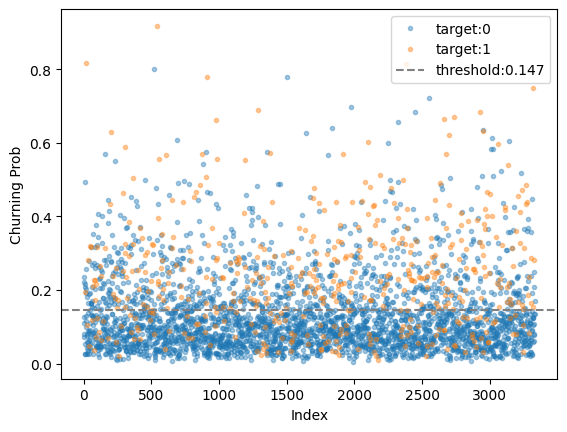

In [ ]:
T=0.5

for target in [0,1]:
    temp_df = model_df[model_df['target']==target]
    plt.plot(temp_df['proba'], '.', alpha=0.4, label='target:{}'.format(target))
plt.axhline(T, color='grey', linestyle='--',label='threshold:{}'.format(T))
plt.xlabel('Index')
plt.ylabel('Churning Prob')
plt.legend()
plt.show()

In [178]:
VP = model_df[(model_df['target']==1)&(model_df['proba']>T)].shape[0]
FP = model_df[(model_df['target']==0)&(model_df['proba']>T)].shape[0]
FN = model_df[(model_df['target']==1)&(model_df['proba']<T)].shape[0]
VN = model_df[(model_df['target']==0)&(model_df['proba']<T)].shape[0]

print('TP:{} FP:{} FN:{} TN:{}'.format(VP, FP, FN, VN))

TP:343 FP:831 FN:140 TN:2019


Cela c'est pour un seuil fixe de valeur 0.5.  
Que ce passe-t-il si on varie cette valeur dans l'intervalle [0,1] ?  
En vue statique, matplotlib, nous aurons: 

In [179]:
threshold_list = np.linspace(0,1,51)

score_df = pd.DataFrame()
score_df['threshold'] = threshold_list

VP_list = []
FP_list = []
VN_list = []
FN_list = []
for threshold in threshold_list:
    VP = model_df[(model_df['target']==1) & (model_df['proba']>threshold)].shape[0]
    FP = model_df[(model_df['target']==0) & (model_df['proba']>threshold)].shape[0]
    VN = model_df[(model_df['target']==0) & (model_df['proba']<threshold)].shape[0]
    FN = model_df[(model_df['target']==1) & (model_df['proba']<threshold)].shape[0]
    VP_list.append(VP)
    FP_list.append(FP)
    VN_list.append(VN)
    FN_list.append(FN)

score_df['VP'] = VP_list
score_df['FP'] = FP_list
score_df['VN'] = VN_list
score_df['FN'] = FN_list

score_df.head()

,threshold,VP,FP,VN,FN
0,0.00,483,2850,0,0
1,0.02,480,2783,67,3
2,0.04,463,2509,341,20
3,0.06,441,2136,714,42
4,0.08,416,1766,1084,67


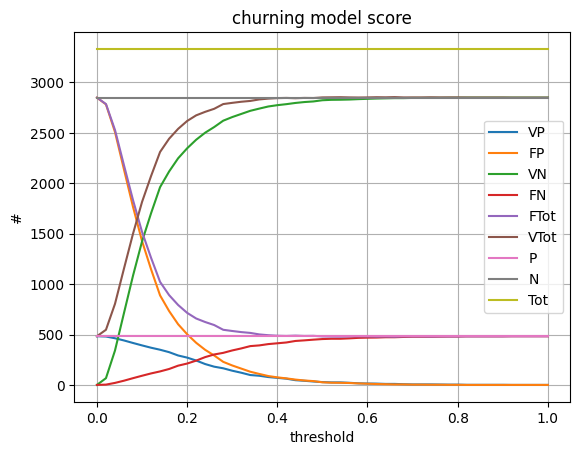

In [180]:
score_df['FTot'] = score_df['FP'] + score_df['FN'] 
score_df['VTot'] = score_df['VP'] + score_df['VN']
score_df['Tot'] = score_df['FTot'] + score_df['VTot']
score_df['P'] = score_df['VP'] + score_df['FN']
score_df['N'] = score_df['VN'] + score_df['FP']

for genre in ['VP', 'FP', 'VN', 'FN','FTot','VTot','P','N','Tot']:
    plt.plot(score_df['threshold'], score_df[genre], label=genre)
    
plt.xlabel('threshold')
plt.ylabel('#')
plt.title('churning model score')
plt.legend()
plt.grid()
plt.show()

Jusqu'ici, nous avons considéré les nombres (TP, FP, FN, TN) constituant la matrice de confusion.  
Ces nombres étant absolus, ils ne seront pas 'portables' d'expérience en expérience...
C'est pourquoi on préfère généralement utiliser des scores reprenant des chiffres relatifs
tous dans l'intervalle [0,1] comme la précision, l'exactitude, la spécificité et la sensibilité (voir tableau de synthèse dans les slides)  

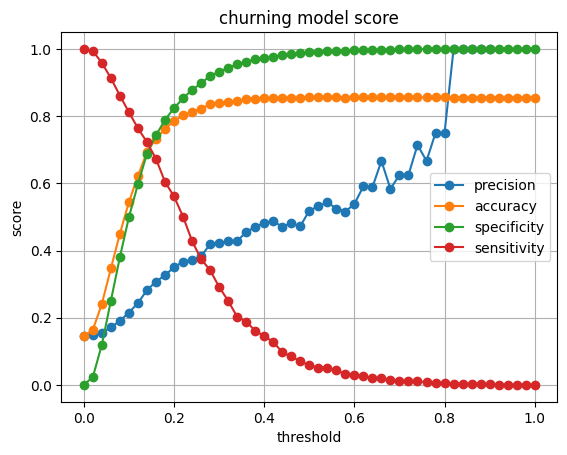

In [181]:
score_df['specificity'] = score_df.apply(lambda r:r['VN']/(r['FP']+r['VN']), axis=1)
score_df['sensitivity'] = score_df.apply(lambda r:r['VP']/(r['VP']+r['FN']), axis=1)
score_df['precision'] = score_df.apply(lambda r:r['VP']/(r['VP']+r['FP']) if r['VP']+r['FP']!=0 else None, axis=1)
score_df['accuracy'] = score_df.apply(lambda r:(r['VP']+r['VN'])/(r['VP']+r['FP']+r['VN']+r['FN']), axis=1)

for genre in ['precision','accuracy','specificity','sensitivity']:
    plt.plot(score_df['threshold'], score_df[genre], '-o', label=genre)
    
plt.xlabel('threshold')
plt.ylabel('score')
plt.title('churning model score')
plt.legend()
plt.grid()
plt.show()

En particulier, on va se concentrer sur deux scores, l'anti-spécificité (1-spécificité) et la sensibilité, 
l'un reporté sur l'axe des x et l'autre sur l'axe des y.  
On obtient alors la vue statique suivante:  

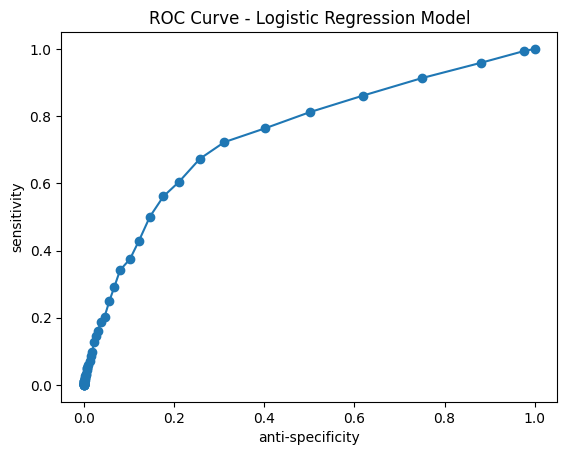

In [182]:
plt.plot(1-score_df['specificity'], score_df['sensitivity'], '-o')
plt.xlabel('anti-specificity')
plt.ylabel('sensitivity')
plt.title('ROC Curve - Logistic Regression Model')
plt.show()

L'accumulation de points au voisinage de (0,0) vous semble-t-elle logique? et pourquoi?  

Généralement, on s'arrange pour les axes x et y soit à la même échelle (aspect ratio == 1).

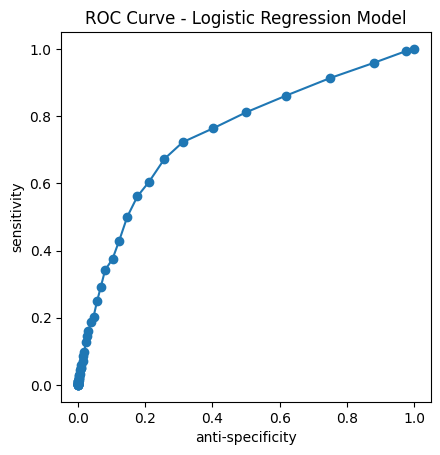

In [183]:
plt.axes().set_aspect('equal')
plt.plot(1-score_df['specificity'], score_df['sensitivity'], '-o')
plt.xlabel('anti-specificity')
plt.ylabel('sensitivity')
plt.title('ROC Curve - Logistic Regression Model')
plt.show()

- Qu'arriverait-il si le modèle était purement hasardeux ?

La courbe ROC se confond exactement avec la diagonale principale reliant le point (0,0) au point (1,1).

AUC = 0.5$

- Qu'arriverait-il si le modèle était parfait ?

la courbe ROC passerait par le point (Anti-spécificité = 0, Sensibilité = 1)

AUC = 1.000 (le maximum théorique absolu).

# E8

- Pour la famille de modèle logisitique optimal, caluler l'anti-spécificité et la sensibilité pour un ensemble de thresholds, T,  équipartis sur l'intervalle [0,1] (c'est fait dans l'E7)

- Pour chaque valeur de T, déterminer la distance au point représentant un modèle parfait situé en (0,1) (coin supérieur gauche).

- Trouver le threshold optimum correspondant au point de la courbe ROC la plus proche de modèle parfait.

- Faite de même en considérant la distance à la diagonale et ici, en maximisant cette distance.

- Trouvez-vous le même threshold optimal ? Commentez ?


In [184]:
score_df['dist2'] = score_df.apply(lambda x: math.sqrt((1-x['specificity'])**2+(x['sensitivity']-1)**2), axis=1)
score_df['dist2diag'] = score_df.apply(lambda x: math.sqrt(2)/2*math.fabs(1-x['specificity']-x['sensitivity']), axis=1)

Attention : 

- sur le slide 57, x est bien l'abscisse et donc 1-x['specificity'] !!! sinon cela ne donne pas la tendance escomptée !!!
- par rapport à la session live, j'ai bien ajouté le facteur sqrt(2)/2 dans la distance à la diagonale

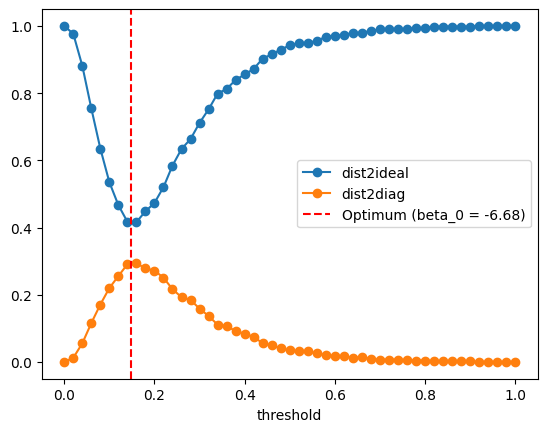

In [ ]:
plt.plot(score_df['threshold'], score_df['dist2'], '-o', label='dist2ideal')
plt.plot(score_df['threshold'], score_df['dist2diag'], '-o', label='dist2diag')

plt.axvline(x=0.147, color='red', linestyle='--')

plt.xlabel('threshold')
plt.legend()
plt.show()

In [186]:
from sklearn.metrics import roc_auc_score
print('{:.3f}'.format(roc_auc_score(model_df['target'], model_df['proba'])))

0.745


- Qu'arriverait-il si le modèle était purement hasardeux ? 

- Qu'arriverait-il si le modèle était parfait ? 

In [187]:
from sklearn.metrics import roc_curve
import numpy as np

# Calcul des taux pour la courbe ROC
fpr, tpr, thresholds = roc_curve(y, model.predict_proba(X)[:, 1])

# Maximisation de l'indice de Youden (Sensibilité + Spécificité - 1 = tpr - fpr)
youden_j = tpr - fpr
opt_idx = np.argmax(youden_j)
optimal_threshold = thresholds[opt_idx]

print(f"Seuil optimal (Youden) : {optimal_threshold:.3f}")

Seuil optimal (Youden) : 0.147
